# 02 · Feature engineering, model training & experiment tracking
The production training entry point is `python -m heart.train`. This notebook inspects the results stored in MLflow.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import os; os.chdir(ROOT)

In [2]:
from heart.features import build_preprocessor, HeartFeatureBuilder
from heart.data import load_clean, split_xy
X, y = split_xy(load_clean())
HeartFeatureBuilder().transform(X).head()

,age,trestbps,chol,thalach,oldpeak,cp,restecg,slope,ca,thal,sex,fbs,exang,hr_reserve_pct,age_oldpeak,st_risk_flag
0,63.0,145.0,233.0,150.0,2.3,1.0,2.0,3.0,0.0,6.0,1.0,1.0,0.0,0.955414,144.9,1.0
1,67.0,160.0,286.0,108.0,1.5,4.0,2.0,2.0,3.0,3.0,1.0,0.0,1.0,0.705882,100.5,1.0
2,67.0,120.0,229.0,129.0,2.6,4.0,2.0,2.0,2.0,7.0,1.0,0.0,1.0,0.843137,174.2,1.0
3,37.0,130.0,250.0,187.0,3.5,3.0,0.0,3.0,0.0,3.0,1.0,0.0,0.0,1.021858,129.5,1.0
4,41.0,130.0,204.0,172.0,1.4,2.0,2.0,1.0,0.0,3.0,0.0,0.0,0.0,0.960894,57.4,0.0


In [3]:
pre = build_preprocessor().fit(X)
print(pre)
print(len(pre.named_steps['preprocess'].get_feature_names_out()), "model features:")
list(pre.named_steps['preprocess'].get_feature_names_out())

Pipeline(steps=[('features', HeartFeatureBuilder()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak',
                                                   'hr_reserve_pct',
                                                   'age_oldpeak',
                                                   'st_risk_flag']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                           

['age',
 'trestbps',
 'chol',
 'thalach',
 'oldpeak',
 'hr_reserve_pct',
 'age_oldpeak',
 'st_risk_flag',
 'cp_1.0',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'restecg_0.0',
 'restecg_1.0',
 'restecg_2.0',
 'slope_1.0',
 'slope_2.0',
 'slope_3.0',
 'ca_0.0',
 'ca_1.0',
 'ca_2.0',
 'ca_3.0',
 'thal_3.0',
 'thal_6.0',
 'thal_7.0',
 'sex',
 'fbs',
 'exang']

## Train all candidates (same code path as `python -m heart.train`)

In [4]:
from heart import train
meta = train.run(quick=False)   # quick=True for a fast smoke run
meta["model_name"], meta["metrics"]["cv_roc_auc_mean"]

            model  cv_accuracy_mean  cv_accuracy_std  cv_precision_mean  cv_precision_std  cv_recall_mean  cv_recall_std  cv_f1_mean  cv_f1_std  cv_roc_auc_mean  cv_roc_auc_std  cv_recall_at_05_mean  cv_recall_at_05_std  cv_precision_at_05_mean  cv_precision_at_05_std  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc  test_accuracy_at_05  test_precision_at_05  test_recall_at_05  test_f1_at_05  test_roc_auc_at_05
  logreg_baseline            0.8427           0.0372             0.8243            0.0698          0.8462         0.0475      0.8324     0.0353           0.9045          0.0145                0.7834               0.0459                   0.8768                  0.0542         0.8852          0.8182       0.9643   0.8852        0.9686               0.8852                0.8387             0.9286         0.8814              0.9686
           logreg            0.8096           0.0347             0.7631            0.0515          0.8553         0.0455      0.8051  

Registered model 'heart-disease-classifier' already exists. Creating a new version of this model...
Created version '4' of model 'heart-disease-classifier'.


('logreg', 0.9052)

## MLflow runs

In [5]:
import mlflow
from heart.config import MLFLOW_TRACKING_URI, MLFLOW_EXPERIMENT
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT])
cols = ["tags.mlflow.runName","metrics.cv_roc_auc_mean","metrics.cv_accuracy_mean","metrics.cv_recall_mean","metrics.test_roc_auc","start_time"]
runs[[c for c in cols if c in runs]].dropna(subset=["metrics.cv_roc_auc_mean"]).sort_values("start_time", ascending=False).head(12)

,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.cv_accuracy_mean,metrics.cv_recall_mean,metrics.test_roc_auc,start_time
0,gradient_boosting,0.883139,0.789116,0.809881,0.957792,2026-10-10 07:46:13.894000+00:00
1,random_forest,0.890964,0.780697,0.809881,0.964286,2026-10-10 07:45:57.213000+00:00
2,logreg,0.905233,0.809609,0.855336,0.969697,2026-10-10 07:45:54.009000+00:00
3,logreg_baseline,0.904535,0.842687,0.846245,0.968615,2026-10-10 07:45:47.032000+00:00
5,gradient_boosting,0.883139,0.789116,0.809881,0.957792,2026-10-10 06:55:20.428000+00:00
6,random_forest,0.890964,0.780697,0.809881,0.964286,2026-10-10 06:55:03.203000+00:00
7,logreg,0.905233,0.809609,0.855336,0.969697,2026-10-10 06:54:59.604000+00:00
8,logreg_baseline,0.904535,0.842687,0.846245,0.968615,2026-10-10 06:54:52.541000+00:00
10,gradient_boosting,0.883139,0.789116,0.809881,0.957792,2026-10-10 06:39:37.086000+00:00
11,random_forest,0.890964,0.780697,0.809881,0.964286,2026-10-10 06:39:05.065000+00:00


In [6]:
import pandas as pd
pd.read_csv("reports/model_comparison.csv")

,model,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,...,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_accuracy_at_05,test_precision_at_05,test_recall_at_05,test_f1_at_05,test_roc_auc_at_05
0,logreg_baseline,0.8427,0.0372,0.8243,0.0698,0.8462,0.0475,0.8324,0.0353,0.9045,...,0.8852,0.8182,0.9643,0.8852,0.9686,0.8852,0.8387,0.9286,0.8814,0.9686
1,logreg,0.8096,0.0347,0.7631,0.0515,0.8553,0.0455,0.8051,0.0330,0.9052,...,0.8689,0.7941,0.9643,0.8710,0.9697,0.8852,0.8387,0.9286,0.8814,0.9697
2,random_forest,0.7807,0.0479,0.7412,0.0607,0.8099,0.0890,0.7708,0.0540,0.8910,...,0.8525,0.7714,0.9643,0.8571,0.9643,0.8852,0.8387,0.9286,0.8814,0.9643
3,gradient_boosting,0.7891,0.0216,0.7616,0.0680,0.8099,0.0792,0.7785,0.0163,0.8831,...,0.8361,0.7647,0.9286,0.8387,0.9578,0.9016,0.8667,0.9286,0.8966,0.9578


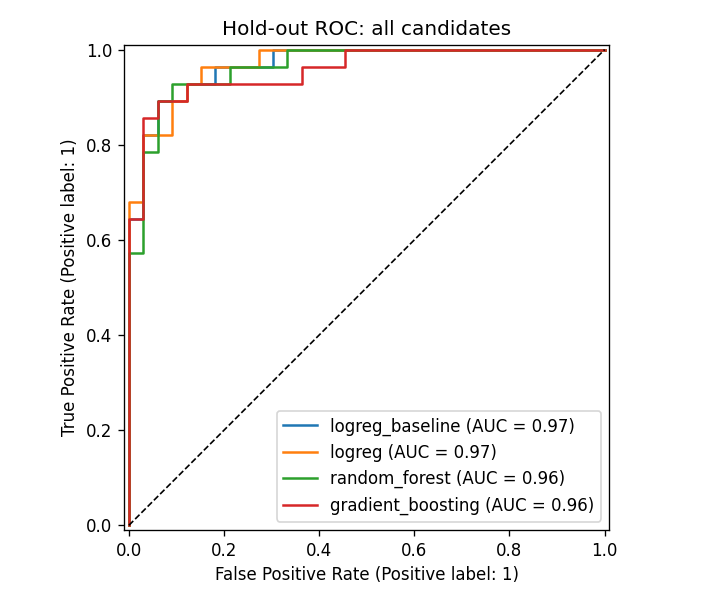

gradient_boosting_evaluation.png


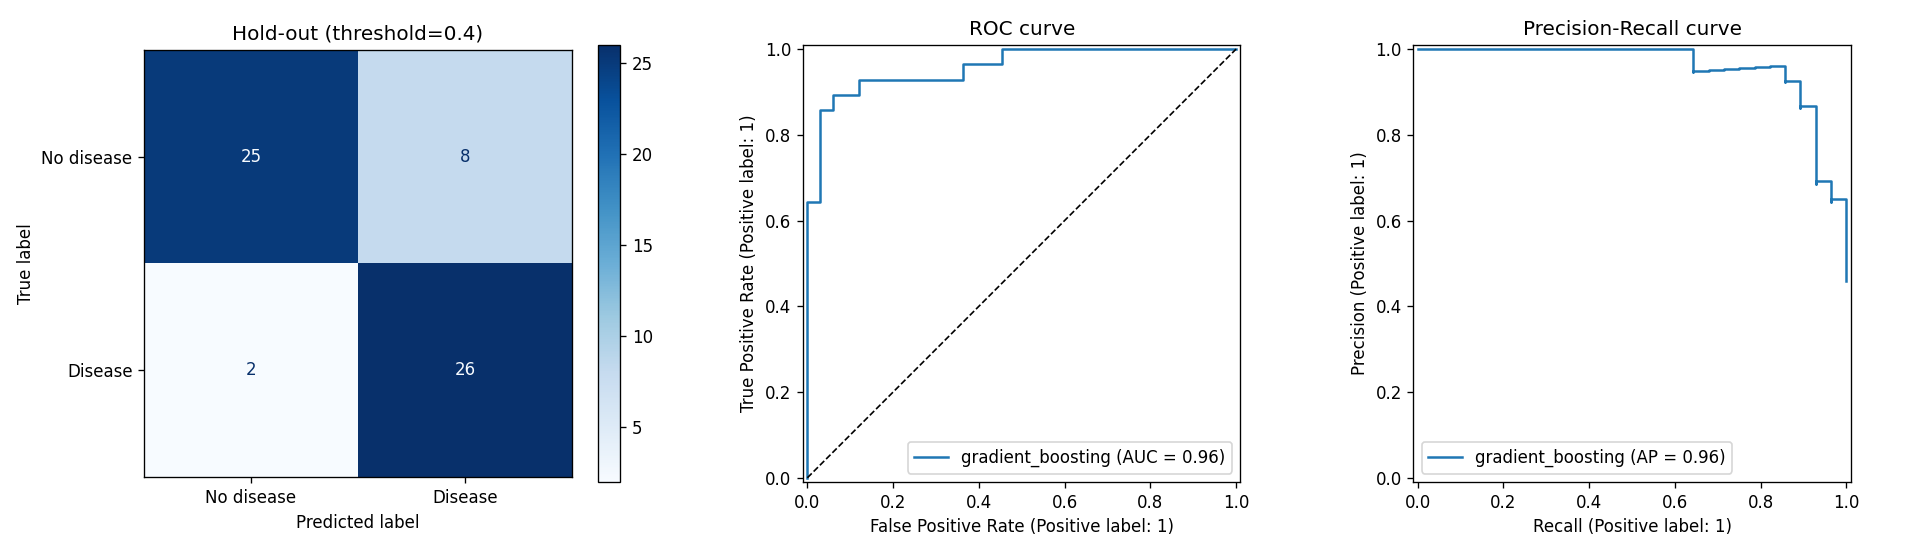

logreg_baseline_evaluation.png


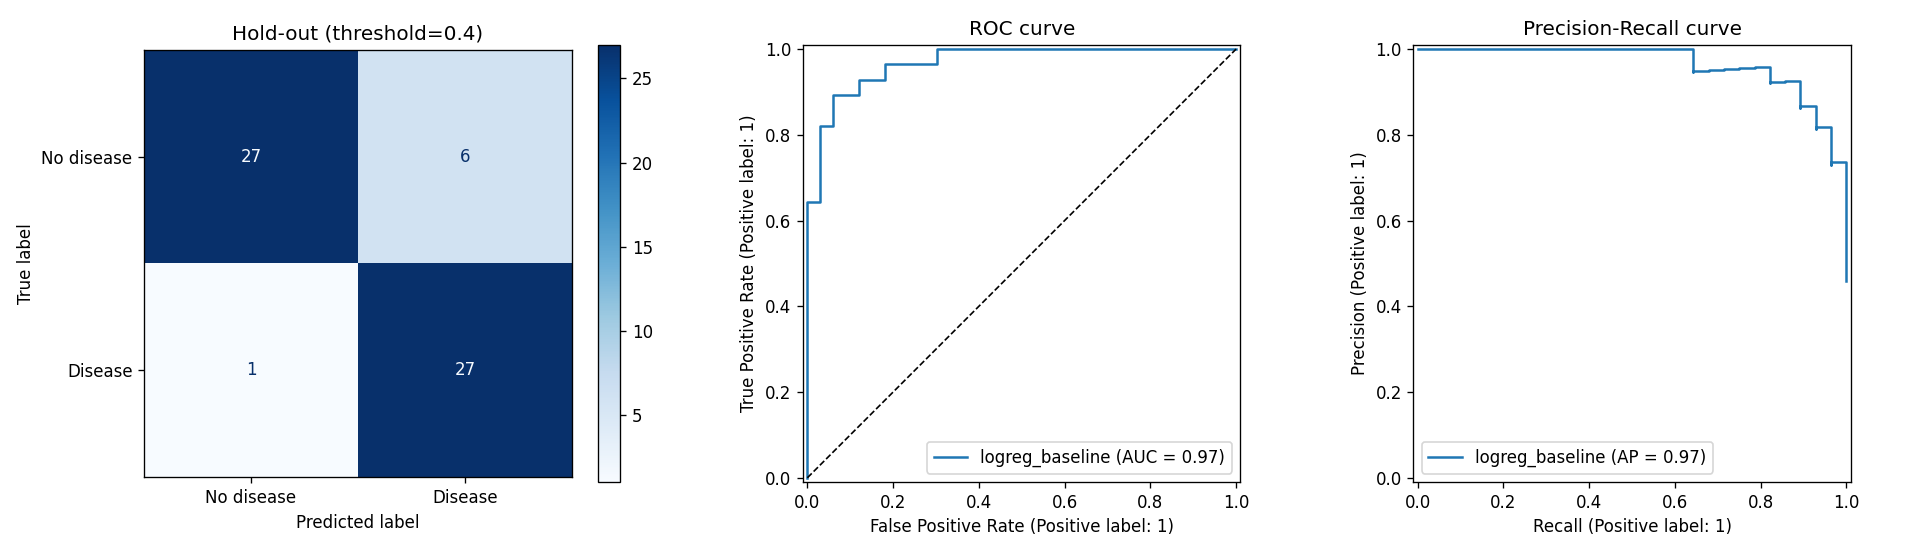

logreg_evaluation.png


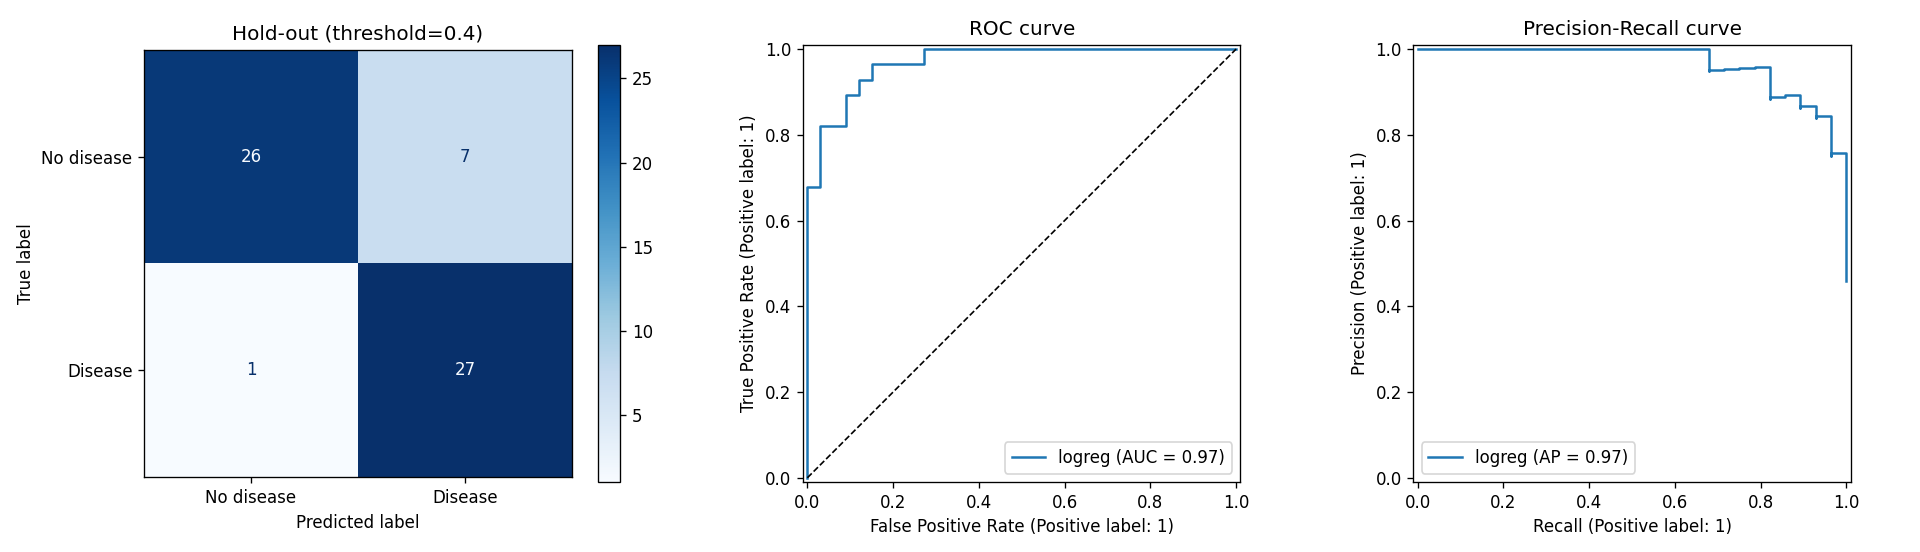

random_forest_evaluation.png


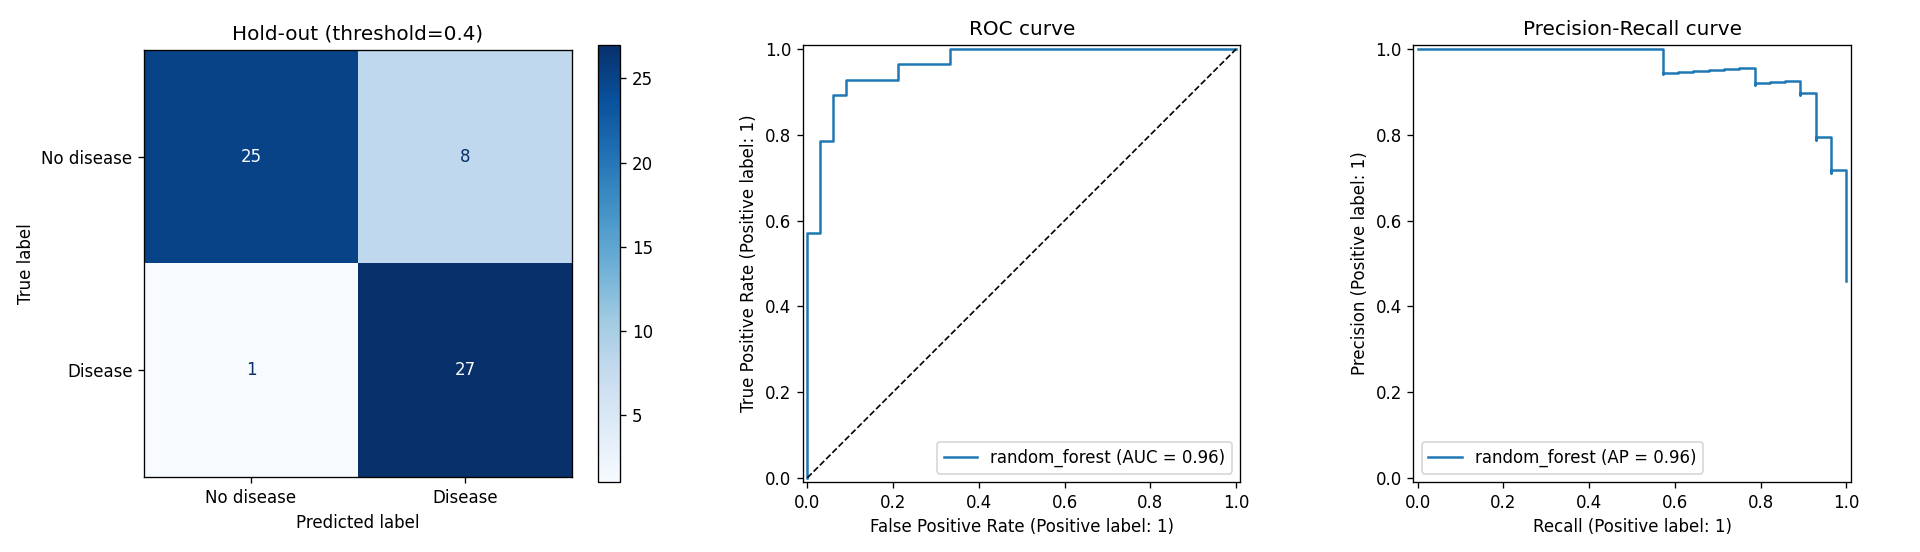

In [7]:
from IPython.display import Image, display
display(Image(filename="reports/figures/models/roc_all_models.png"))
for f in sorted((ROOT/"reports/figures/models").glob("*_evaluation.png")):
    print(f.name); display(Image(filename=str(f)))

## Model selection notes

I would keep `logreg` for this version because it has the highest mean training CV ROC-AUC (0.9052) under the selection rule. I use the same five folds for all four candidates and keep the raw-feature logistic model as an ablation. The hold-out scores do not decide the winner, including when CV scores tie.

I replaced `chol_per_age` with `age_oldpeak = age * oldpeak` to test whether the ST-depression signal changes with age. The plots motivate this experiment, but they do not prove that the interaction helps. I would judge it against the baseline, rather than assume that adding a feature improves the model. In the exported model, L1 regularisation sets the `age_oldpeak` coefficient to zero, so this run does not show a benefit from the new interaction.

I set the decision threshold to 0.4 before this run to put more weight on finding disease cases. At this threshold, mean CV recall is 0.8553 and precision is 0.7631; at 0.5 they are 0.7739 and 0.8696. This makes the trade-off visible instead of reporting recall alone. The API reads the same threshold from the exported metadata, and CI requires mean CV recall >= 0.80 and mean CV ROC-AUC >= 0.85.

On the 61-row hold-out set, recall is 0.9643, precision is 0.7941, and ROC-AUC is 0.9697. These are results for one small split. The CV folds were also used for hyperparameter tuning, so their scores are not an independent estimate. I would use nested CV or a separate validation dataset before making stronger claims. The hold-out has been reviewed during this project, so a fresh external dataset is needed for an independent final check.
